# Predict customers that are likely to upgrade

## Libraries and common functions

In [ ]:
# model output explanation library
!pip install shap

In [ ]:
import os
import pickle
from tqdm import tqdm

import pandas as pd
import numpy as np
from scipy.stats import ks_2samp
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive

In [ ]:
# display defaults
pd.options.display.max_columns = None
plt.rcParams['axes.axisbelow'] = True
plt.rcParams['axes.grid'] = True

In [ ]:
# classification model quality visualization
from sklearn.metrics import confusion_matrix
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import f1_score

def plot_confusion_matrix(conf_mat):
  plt.figure()
  group_names = ['True Negative', 'False Positive', 'False Negative', 'True Positive']

  group_counts = ["{0:,d}".format(value) for value in
                  conf_mat.flatten()]

  group_percentages = ["{0:.2%}".format(value) for value in
                        conf_mat.flatten() / np.sum(conf_mat)]

  labels = [f"{v1}\n\n{v2}\n\n{v3}" for v1, v2, v3 in
            zip(group_names, group_counts, group_percentages)]

  labels = np.asarray(labels).reshape(2, 2)

  ax = sns.heatmap(conf_mat, annot=labels, fmt='', cmap='Blues', annot_kws={"weight": "bold"})  # cmap='Blues'

  ax.set_title('Actual vs Predicted Labels\n')
  ax.set_xlabel('Predicted Labels').set_weight("bold")
  ax.set_ylabel('Actual Labels ').set_weight("bold")

  tick_labels = ['stayed free', 'upgraded']
  ax.xaxis.set_ticklabels(tick_labels)
  ax.yaxis.set_ticklabels(tick_labels)

  return plt


def plot_roc_curve(y_true, y_scores):
  plt.figure()
  fpr, tpr, thresholds = roc_curve(y_true, y_scores, pos_label=1)
  plt.plot(fpr, tpr, color="darkorange", linewidth=2,
           label="ROC curve (area = %0.2f)" % auc(fpr, tpr))
  plt.plot([0, 1], [0, 1], '--', color="navy")
  plt.axis([0, 1, 0, 1])
  plt.title("Receiver Operating Characteristic")
  plt.xlabel('False Positive Rate')
  plt.ylabel('True Positive Rate')
  plt.legend(loc="lower right")

  return plt


def plot_precision_recall_vs_threshold(y_true, y_scores):
  plt.figure()
  precisions, recalls, thresholds = precision_recall_curve(y_true, y_scores)
  plt.plot(thresholds, precisions[:-1], "b--", label="Precision")
  plt.plot(thresholds, recalls[:-1], "g-", label="Recall")
  plt.title("Precision-Recall Tradeoff")
  plt.xlabel("Threshold")
  plt.legend(loc="upper left")
  plt.ylim([0, 1])

  return plt


def display_classifier_performance_stats(clf, X_test, y_test, threshold=0.5):
  # get positive class predictions probabilityes the test set
  y_pred_proba = clf.predict_proba(X_test)[:,1]

  # get the labels
  y_pred = y_pred_proba > threshold

  cm = confusion_matrix(y_test, y_pred)

  plot_confusion_matrix(cm)
  plot_roc_curve(y_test, y_pred_proba)
  plot_precision_recall_vs_threshold(y_test, y_pred_proba)

  tn, fp, fn, tp = cm.ravel()
  print(f"Type I Error (fpr)          = {fp / (fp + tn):.4f}")
  print(f"Type II Error (fnr)         = {fn / (tp + fn):.4f}")
  print(f"Specificity (tnr)           = {tn / (tn + fp):.4f}")
  print(f"Precision                   = {tp / (tp + fp):.4f}")
  print(f"Recall (Sensitivity or tpr) = {tp / (tp + fn):.4f}")
  print(f"F1 Score                    = {f1_score(y_test, y_pred):.4f}")

  ks = ks_2samp(y_pred_proba[y_test == 0.0],
                y_pred_proba[y_test != 0.0])
  print(f"Kolmogorov-Smirnov score    = {ks.statistic:.4f}")

  print()

In [ ]:
# setting up google drive directory to load the data and save the results
MOUNTPOINT = '/content/gdrive'
MIRO_DIR = os.path.join(MOUNTPOINT, 'MyDrive', 'Colab Notebooks', 'MIRO') # google drive path to the folder with the zip file
DATA_DIR = os.path.join(MIRO_DIR, 'ds_test_2') # path to the unzipped folder
drive.mount(MOUNTPOINT)

Mounted at /content/gdrive


# Pull the data

## Read tables into pandas dataframes

In [ ]:
# extract files
import zipfile
with zipfile.ZipFile(os.path.join(MIRO_DIR, 'ds_test_v2.zip'), 'r') as zip_ref:
    zip_ref.extractall(MIRO_DIR)

In [ ]:
# read tables and display basic columns statistics
data_files = os.listdir(DATA_DIR)
def get_df(file_name): return pd.read_csv(os.path.join(DATA_DIR, file_name))

dfs = {}

pd.options.display.float_format = '{:,.2f}'.format
for file_name in data_files:
  df = get_df(file_name)
  # count values of -1 as missing
  df = df.replace(-1,np.NaN)
  df['time'] = pd.to_datetime(df['time'])
  # remove '.csv' from the name
  dfs[file_name[:-4]] = df
  # display basic stats
  print()
  print(f"{file_name:>20} | {df.shape[0]:,d} rows | {df.shape[1]} columns |", end=' ')
  print(f"{len(df['account_id'].drop_duplicates()):,d} unique accounts")
  print(f"{' '*20} | Time from {min(df['time'])}")
  print(f"{' '*20} |        to {max(df['time'])}")
  display(df.describe())
pd.options.display.float_format = '{:g}'.format


        accounts.csv | 11,027,924 rows | 8 columns | 442,783 unique accounts
                     | Time from 2018-04-15 00:00:00
                     |        to 2019-03-10 00:00:00


,account_age_days,company_domain,target,account_id,domain
count,"11,027,924.00","11,027,924.00","11,027,924.00","11,027,924.00","3,755,965.00"
mean,122.76,0.34,0.00,"146,185.93","41,932.24"
std,85.97,0.47,0.07,"105,432.34","23,907.17"
min,7.00,0.00,0.00,0.00,0.00
25%,49.00,0.00,0.00,"58,220.00","21,244.00"
50%,105.00,0.00,0.00,"125,277.00","42,459.00"
75%,182.00,1.00,0.00,"218,663.00","63,624.00"
max,364.00,1.00,1.00,"442,782.00","81,868.00"



   collab_boards.csv | 179,441 rows | 8 columns | 58,805 unique accounts
                     | Time from 2018-03-18 00:00:00
                     |        to 2019-06-23 00:00:00


,collab_boards,collab_sync_boards,mean_editors,std_editors,sum_editors,sync_boards_part,account_id
count,"179,441.00","179,441.00","179,441.00","179,441.00","179,441.00","179,441.00","179,441.00"
mean,1.69,0.86,2.73,0.12,4.76,0.51,"208,516.67"
std,1.55,1.26,1.77,0.66,6.22,0.48,"121,785.80"
min,1.00,0.00,2.00,0.00,2.00,0.00,96.00
25%,1.00,0.00,2.00,0.00,2.00,0.00,"109,201.00"
50%,1.00,1.00,2.00,0.00,2.00,0.50,"200,369.00"
75%,2.00,1.00,3.00,0.00,5.00,1.00,"307,177.00"
max,56.00,51.00,159.00,93.34,302.00,1.00,"442,782.00"



           seats.csv | 599,825 rows | 3 columns | 442,776 unique accounts
                     | Time from 2018-03-11 00:00:00
                     |        to 2019-07-21 00:00:00


,occupied,account_id
count,"599,825.00","599,825.00"
mean,6.74,"222,207.56"
std,34.72,"126,895.98"
min,1.00,0.00
25%,1.00,"114,148.00"
50%,1.00,"221,497.00"
75%,3.00,"331,767.00"
max,"1,983.00","442,782.00"


... (2 outputs left out)


    board_loaded.csv | 135,526 rows | 15 columns | 40,372 unique accounts
                     | Time from 2018-03-18 00:00:00
                     |        to 2019-03-17 00:00:00


,n_loads,load_time_mean,load_time_std,is_guest,app_type_0.0,app_type_1.0,app_type_2.0,app_type_3.0,app_type_4.0,app_type_5.0,app_type_6.0,app_type_nan,average_clustering,account_id
count,"135,526.00","135,526.00","135,526.00","135,526.00","135,526.00","135,526.00","135,526.00","135,526.00","135,526.00","135,526.00","135,526.00","135,526.00","135,526.00","135,526.00"
mean,29.23,"298,637.73","890,908.76",0.09,25.58,2.76,0.36,0.05,0.23,0.19,0.07,0.00,0.82,"200,627.33"
std,56.05,"4,943,144.00","10,929,728.97",1.43,53.12,8.91,2.97,1.01,2.72,2.12,1.18,0.00,0.35,"119,758.45"
min,3.00,"-146,141,426.54",0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,107.00
25%,9.00,"7,313.52","5,232.81",0.00,8.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.86,"103,125.25"
50%,17.00,"13,578.25","14,987.07",0.00,15.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,"190,586.00"
75%,33.00,"29,844.30","44,457.37",0.00,29.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,"296,780.00"
max,"11,463.00","1,135,423,487.67","1,966,598,863.39",173.00,"11,463.00",539.00,732.00,173.00,284.00,327.00,159.00,0.00,1.00,"442,782.00"



    boards_stats.csv | 627,255 rows | 30 columns | 408,534 unique accounts
                     | Time from 2018-01-07 00:00:00
                     |        to 2019-03-10 00:00:00


,board_usecase_balanced_scorecard,board_usecase_blueprint,board_usecase_brainstorming,board_usecase_business_modeling,board_usecase_dedicated_team_boards,board_usecase_design,board_usecase_diagramming,board_usecase_fishbone,board_usecase_gantt_chart,board_usecase_kanban/scrum_board,board_usecase_mapping,board_usecase_meeting_notes,board_usecase_monthly_planner,board_usecase_organization_structure,board_usecase_process/workflow/flow,board_usecase_product_development,board_usecase_product_management,board_usecase_project_planning,board_usecase_retrospective/retro,board_usecase_roadmap,board_usecase_sprint_planning,board_usecase_story_map/journey_map,board_usecase_strategizing,board_usecase_timeline,board_usecase_value_proposition,board_usecase_workshop/meetup,board_usecase_nan,n_boards_created,account_id
count,"627,255.00","627,255.00","627,255.00","627,255.00","627,255.00","627,255.00","627,255.00","627,255.00","627,255.00","627,255.00","627,255.00","627,255.00","627,255.00","627,255.00","627,255.00","627,255.00","627,255.00","627,255.00","627,255.00","627,255.00","627,255.00","627,255.00","627,255.00","627,255.00","627,255.00","627,255.00","627,255.00","627,255.00","627,255.00"
mean,0.00,0.00,0.01,0.08,0.00,0.02,0.05,0.00,0.00,0.00,0.03,0.00,0.02,0.07,0.48,0.06,0.00,0.02,0.13,0.11,0.04,0.46,0.01,0.01,0.01,0.00,1.46,3.07,"211,313.33"
std,0.13,0.08,0.18,0.63,0.07,0.27,0.49,0.01,0.01,0.04,0.37,0.08,0.21,0.62,1.66,0.62,0.12,0.22,0.82,0.73,0.37,1.65,0.27,0.20,0.21,0.11,1.74,4.07,"124,395.29"
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00
25%,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,1.00,"105,704.50"
50%,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,1.00,"207,375.00"
75%,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,2.00,4.00,"314,343.50"
max,16.00,10.00,45.00,40.00,8.00,41.00,52.00,3.00,3.00,6.00,99.00,12.00,12.00,80.00,80.00,330.00,15.00,14.00,68.00,40.00,45.00,120.00,74.00,35.00,89.00,28.00,200.00,369.00,"442,782.00"


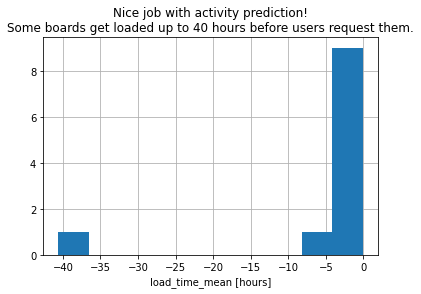

In [ ]:
(dfs['board_loaded'][lambda df: df['load_time_mean'] < 0]['load_time_mean']*(1/(1000*60*60))).hist()
plt.xlabel('load_time_mean [hours]')
plt.title('Nice job with activity prediction!\nSome boards get loaded up to 40 hours before users request them.');

## Check for missing values


accounts
Missing values proportions:


company_size   0.389594
domain         0.659413
dtype: float64

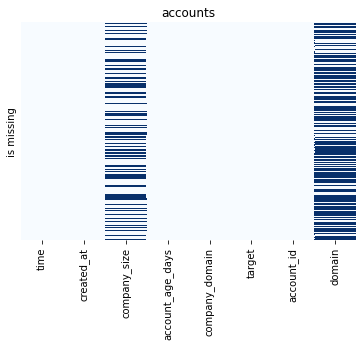


collab_boards
Missing values proportions:


Series([], dtype: float64)

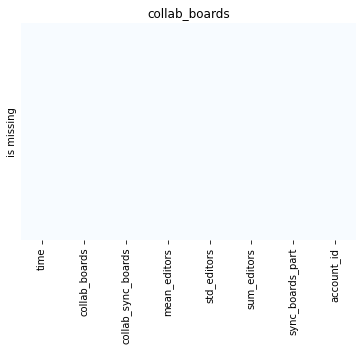


seats
Missing values proportions:


Series([], dtype: float64)

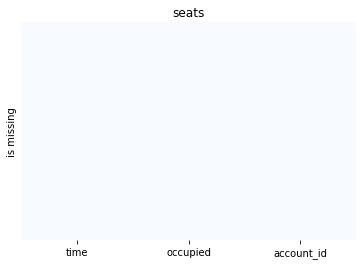


active_boards
Missing values proportions:


Series([], dtype: float64)

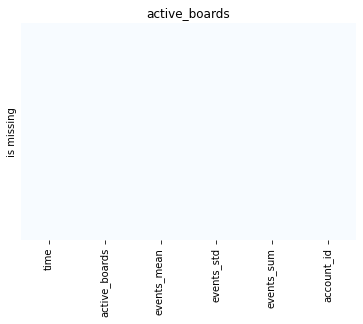


board_loaded
Missing values proportions:


Series([], dtype: float64)

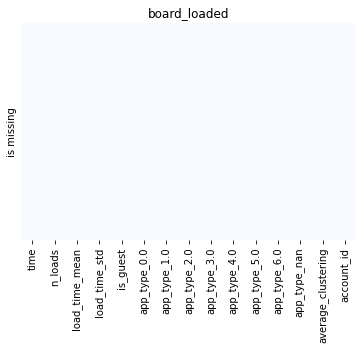


boards_stats
Missing values proportions:


Series([], dtype: float64)

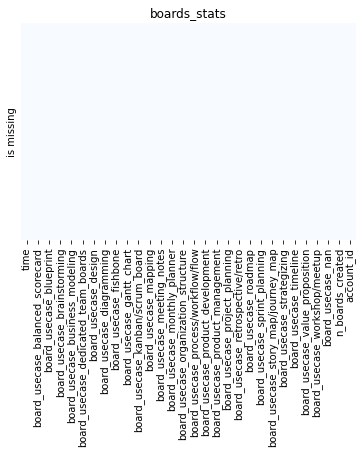

In [ ]:
for name, df in dfs.items():
  plt.figure()
  print()
  print(f'{name}\nMissing values proportions:')
  display(df.isnull().sum(axis=0)[lambda s:s>0]/len(df))
  sns.heatmap(df.sample(min(int(1e4), len(df))).isnull(),
              yticklabels = False, cbar = False, cmap="Blues")
  plt.title(f'{name}')
  plt.ylabel('is missing')
  plt.show()

Will use the **domain** column in train test split to avoid data leakage

Will fill in the missing **company_size** values if the algorithm requires that

# 1. Naive approach (Baseline)
The idea is to take columns and labels as is and fit a linear regressor.

The results can work as a baseline for future iterations if the results are not satisfactory.

## 1.1 Form the training dataset

In [ ]:
# get features columns
subset = [c for c in dfs['accounts'].columns if c not in ['time', 'account_age_days']]

# get rows with the weeks corresponding to upgrade (change of target from 0.0 to 1.0)
df_conversion_week = (
    dfs['accounts']
    .sort_values(['account_id', 'time'])
    # remove all non upgrade weeks
    [lambda df:df['target'] != 0.0]
    # keep the earliest record with the conversion
    # because the further events are not relevant for the propensity to upgrade
    .drop_duplicates(subset=subset, keep='first')
    .copy()
)

# get all weeks where the upgrade did not happen
df_no_conversion_week = (
    dfs['accounts']
    [lambda df:df['target'] == 0.0]
    .copy()
)

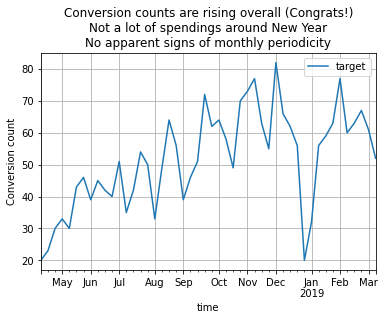

In [ ]:
# check for possible seasonality in upgrade behavior
df_conversion_week.groupby('time')[['target']].sum().plot()
plt.title('Conversion counts are rising overall (Congrats!)'
          '\nNot a lot of spendings around New Year'
          '\nNo apparent signs of monthly periodicity')
plt.ylabel('Conversion count');

In [ ]:
# create the overall labeled dataset
df_labeled = pd.concat([df_conversion_week, df_no_conversion_week]).copy()

# join with other datasets for extra features
for name, df in dfs.items():
  # skip the accounts dataset
  if name in ['accounts']:
    continue
  df_labeled = df_labeled.merge(df, on=['time', 'account_id'])

# transform company size to numeric
df_labeled['company_size'] = df_labeled['company_size'].astype(str).apply(lambda s: float(s.split(' ')[0]))
# fill nulls with the median value
df_labeled['company_size'] = df_labeled['company_size'].fillna(df_labeled['company_size'].median())

# drop the remaining non-numeric columns
df_labeled = df_labeled.drop(columns=['created_at', 'time', 'domain'])

df_labeled['target'].value_counts()

0    21310
1      798
Name: target, dtype: int64

Observations:

*   The number of samples is small
*   The dataset is unballanced



In [ ]:
# split on training and testing
from sklearn.model_selection import train_test_split

# make sure training and testing have the same proportion of labels
train_set, test_set = train_test_split(df_labeled, test_size=0.2, random_state=42, stratify=df_labeled['target'])
X_train = train_set.drop(columns=['target'])
y_train = train_set['target'].copy()
X_test = test_set.drop(columns=['target'])
y_test = test_set['target'].copy()

## 1.2 Train the model

In [ ]:
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# define the model pipeline
clf = make_pipeline(StandardScaler(), # scale the features
                    SGDClassifier(loss='log'))  # linear classifier with a decreasing step size

# fit the training data
clf.fit(X_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('sgdclassifier', SGDClassifier(loss='log'))])

## 1.3 Assess model performance

Type I Error (fpr)          = 0.0049
Type II Error (fnr)         = 0.9812
Specificity (tnr)           = 0.9951
Precision                   = 0.1250
Recall (Sensitivity or tpr) = 0.0187
F1 Score                    = 0.0326
Kolmogorov-Smirnov score    = 0.3903



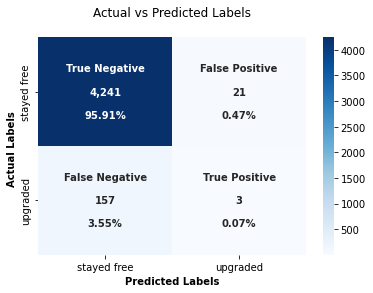

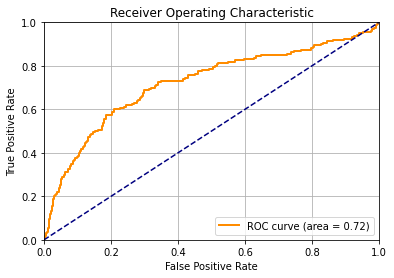

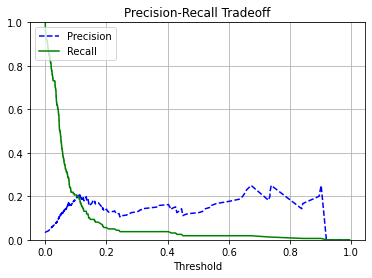

In [ ]:
display_classifier_performance_stats(clf, X_test, y_test)

## <font color='red'>FAIL!</font>
### Potential issues
* Class imballance
* Non informative features
* Wrong model
* Model hyperparameters are not tuned well

One other caveat is that I was using the features at the week of the potential conversion while I don't have these features at requested week of March 14.

#2. A more involved approach

Will try to address all the identified issues

## 2.1 Relabel data
This time I would put a label that corresponds to the next week's target. This way the prediction about the week of March 14 can be based on features from the preceeding week.

In [ ]:
dfs['accounts'] = dfs['accounts'].sort_values(['account_id', 'time'])

df_converted_accounts = (
    dfs['accounts']
    [lambda df:df['target'] > 0.0]
    .drop_duplicates(subset=['account_id'])
    [['account_id', 'target']]
)

df_last_non_conversion_week_labeled = (
    dfs['accounts']
    [lambda df:df['target'] == 0.0]
    # take the last week with no conversion
    .drop_duplicates(subset=['account_id'], keep='last')
    .drop(columns=['target'])
    # add conversion labels based on the following week events
    .merge(df_converted_accounts, on=['account_id'], how='left')
    # fill in non conversions
    .assign(target = lambda df:df['target'].fillna(0.0))
)

df_labeled_data = (
    # union non conversions and last week status labels
    pd.concat([dfs['accounts'][lambda df:df['target'] == 0.0],
               df_last_non_conversion_week_labeled[dfs['accounts'].columns]])
    # keep only the labeled last week
    .drop_duplicates(subset=['account_id', 'time'], keep='last')
)

# transform company size to numeric
df_labeled_data['company_size_num'] = df_labeled_data['company_size'].astype(str).apply(lambda s: float(s.split(' ')[0]))

df_labeled_data['target'].value_counts()

0.0    10972096
1.0        2155
Name: target, dtype: int64

## 2.2 Check feature importance
Looking at how well a predictor can differentiate between classes

In [ ]:
def plot_class_distributions(df, col):
  plt.figure(figsize=(5, 4))
  bins = np.linspace(np.nanquantile(df[col], 0.05), np.nanquantile(df[col], 0.95), num=30)
  if max(bins) == min(bins):
    bins = np.linspace(np.nanmin(df[col]), np.nanmax(df[col]), num=30)
  if max(bins) == min(bins):
    print(f'Values in column {col} are all identical')
    return
  not_converted = df[df['target'] == 0][col]
  converted = df[df['target'] != 0][col]
  not_converted.plot.hist('b', bins=bins, density=True, alpha=0.5, label='not converted')
  converted.plot.hist('r', bins=bins, density=True, alpha=0.5, label='converted')
  plt.title(f'Class separation power: {ks_2samp(converted, not_converted).statistic:.2f}')
  plt.xlabel(col)
  plt.legend()

### accounts

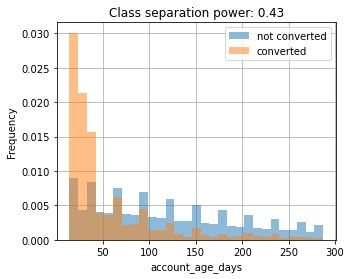

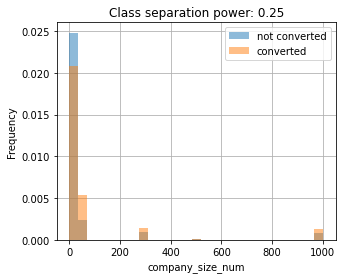

In [ ]:
for col in ['account_age_days', 'company_size_num']:
  plot_class_distributions(df_labeled_data, col)

Check how well other features can distinguish between converters and non-converters

In [ ]:
def get_features_stats(df_nm, cum_features=[], extra_features=[]):
  dfs[df_nm] = dfs[df_nm].sort_values(['account_id', 'time'])

  # add cumulative features
  for col in tqdm(cum_features):
    if f'{col}_cumsum' in dfs[df_nm].columns:
      continue
    dfs[df_nm][f'{col}_cumsum'] = dfs[df_nm].groupby('account_id')[col].transform(pd.Series.cumsum)

  # add the labels
  dfs[df_nm] = (
      dfs[df_nm]
      .merge(df_labeled_data[['time', 'account_id', 'target']])
  )
  display(dfs[df_nm]['target'].value_counts())
  display(dfs[df_nm].sample(2))

  # plots
  #   remove the prediction labels (they are unknown)
  valid_labels = dfs[df_nm]['time'] < max(dfs['accounts']['time'].drop_duplicates())
  df_plot = dfs[df_nm][valid_labels]
  #   plot
  for col in cum_features:
    for suf in ['', '_cumsum']:
      plot_class_distributions(df_plot, f'{col}{suf}')
  for col in extra_features:
    plot_class_distributions(df_plot, f'{col}')

### active_boards

100%|██████████| 3/3 [02:57<00:00, 59.28s/it]


0.0    428501
1.0      1420
Name: target, dtype: int64

,time,active_boards,events_mean,events_std,events_sum,account_id,active_boards_cumsum,events_mean_cumsum,events_sum_cumsum,target
348306,2019-02-17,5,80.6,43.379719,403.0,315147,19,9495.8,26999.0,0.0
392789,2019-01-20,1,2607.0,0.000000,2607.0,371780,2,4796.0,4796.0,0.0


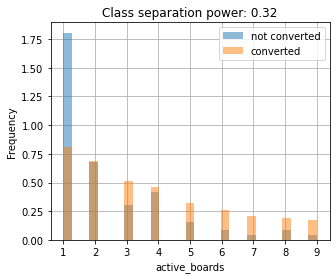

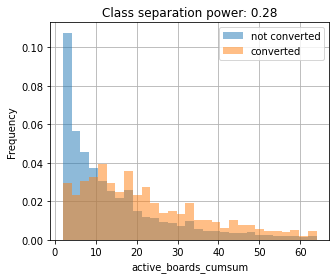

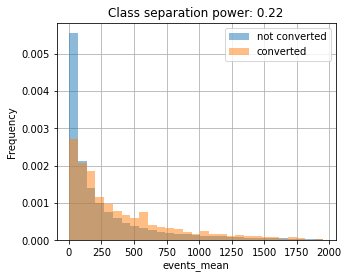

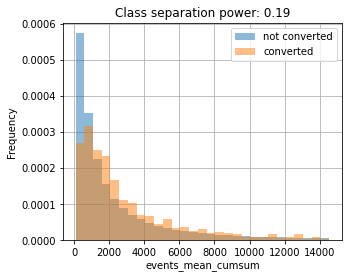

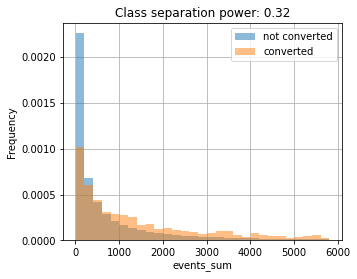

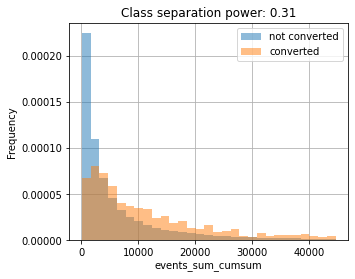

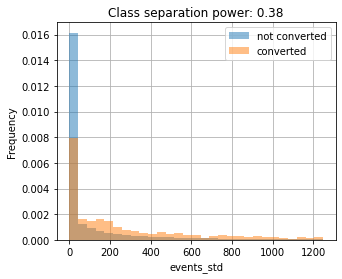

In [ ]:
get_features_stats('active_boards',
                   cum_features = ['active_boards', 'events_mean', 'events_sum'],
                   extra_features = ['events_std'])

### seats

0it [00:00, ?it/s]


0.0    96901
1.0      589
Name: target, dtype: int64

,time,occupied,account_id,target
49818,2018-09-30,7.0,206964,0.0
27779,2018-12-23,6.0,127651,0.0


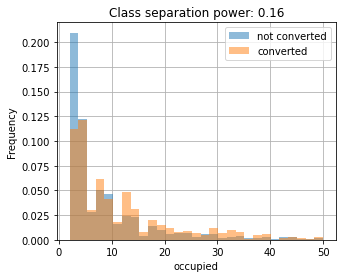

In [ ]:
get_features_stats('seats',
                   extra_features = ['occupied'])

### board_loaded

100%|██████████| 1/1 [00:08<00:00,  8.90s/it]


0.0    90139
1.0      836
Name: target, dtype: int64

,time,n_loads,load_time_mean,load_time_std,is_guest,app_type_0.0,app_type_1.0,app_type_2.0,app_type_3.0,app_type_4.0,app_type_5.0,app_type_6.0,app_type_nan,average_clustering,account_id,n_loads_cumsum,target
44989,2019-03-03,23.0,51809.173913,70718.996143,0.0,23.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,195336,144.0,0.0
14391,2018-05-13,9.0,0.000000,0.000000,0.0,9.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,71824,9.0,0.0


Values in column app_type_nan are all identical


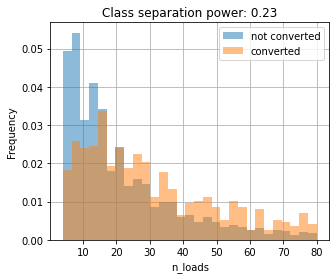

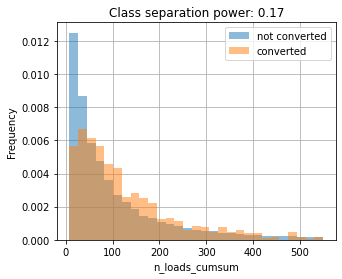

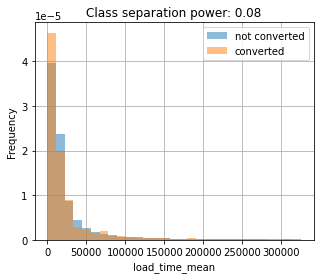

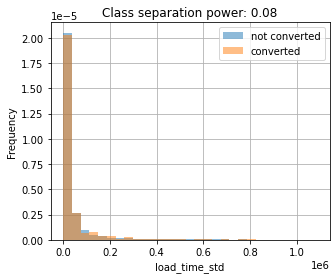

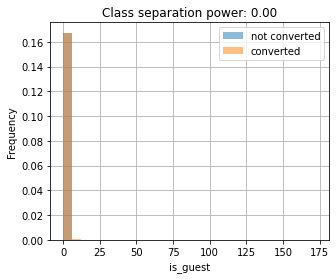

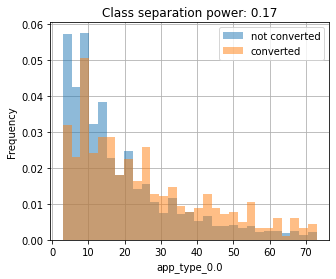

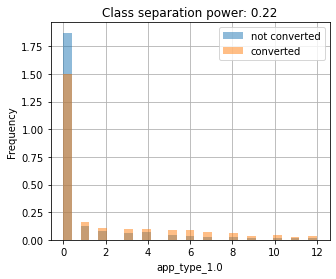

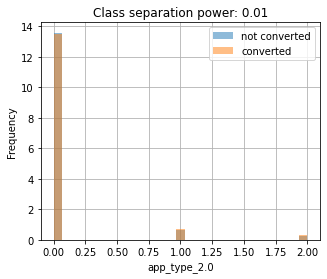

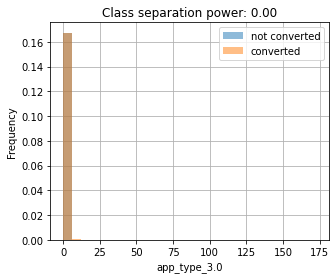

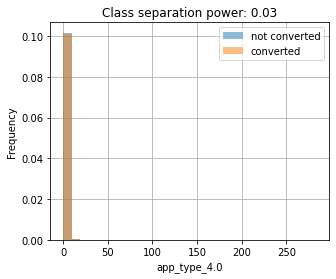

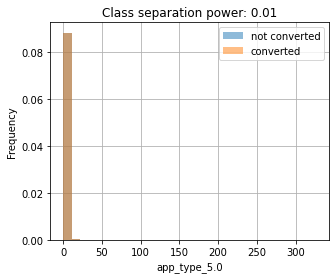

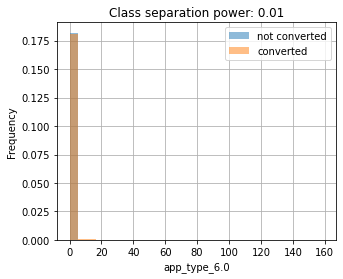

<Figure size 360x288 with 0 Axes>

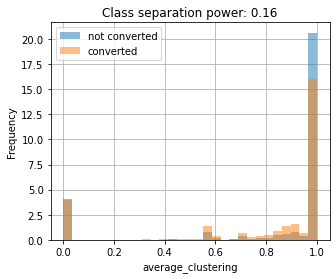

In [ ]:
get_features_stats('board_loaded',
                   cum_features = ['n_loads'],
                   extra_features = [c for c in dfs['board_loaded'].columns if c not in ['time', 'n_loads','account_id', 'target']])

### collab_boards

0it [00:00, ?it/s]


0.0    111079
1.0       779
Name: target, dtype: int64

,time,collab_boards,collab_sync_boards,mean_editors,std_editors,sum_editors,sync_boards_part,account_id,target
25065,2018-10-21,2,2.0,3.0,1.414214,6.0,1.0,98922,0.0
54035,2019-02-24,4,4.0,3.0,0.000000,12.0,1.0,190258,0.0


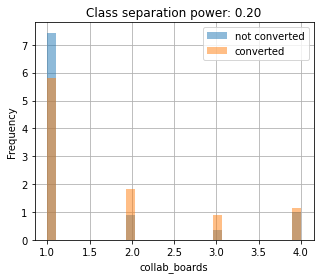

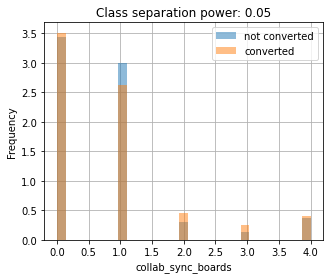

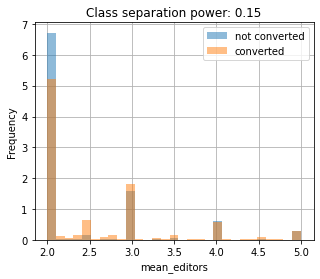

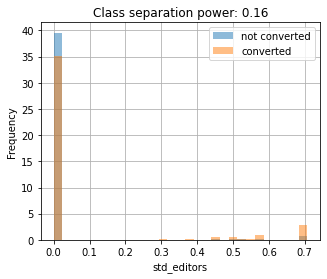

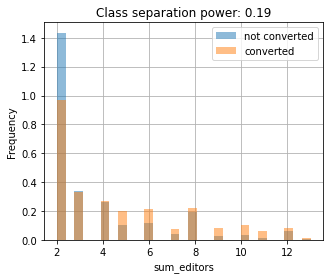

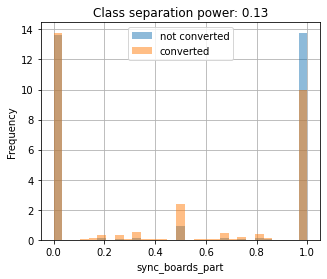

In [ ]:
get_features_stats('collab_boards',
                   extra_features = [c for c in dfs['collab_boards'].columns if c not in ['time', 'account_id', 'target']])

### boards_stats

100%|██████████| 1/1 [01:36<00:00, 96.10s/it]


0.0    197870
1.0       918
Name: target, dtype: int64

,time,board_usecase_balanced_scorecard,board_usecase_blueprint,board_usecase_brainstorming,board_usecase_business_modeling,board_usecase_dedicated_team_boards,board_usecase_design,board_usecase_diagramming,board_usecase_fishbone,board_usecase_gantt_chart,board_usecase_kanban/scrum_board,board_usecase_mapping,board_usecase_meeting_notes,board_usecase_monthly_planner,board_usecase_organization_structure,board_usecase_process/workflow/flow,board_usecase_product_development,board_usecase_product_management,board_usecase_project_planning,board_usecase_retrospective/retro,board_usecase_roadmap,board_usecase_sprint_planning,board_usecase_story_map/journey_map,board_usecase_strategizing,board_usecase_timeline,board_usecase_value_proposition,board_usecase_workshop/meetup,board_usecase_nan,n_boards_created,account_id,n_boards_created_cumsum,target
48856,2018-07-01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,106266,2.0,0.0
176119,2019-01-13,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0,361565,23.0,0.0


/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:2: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  
/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:2: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  
/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:2: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warnin

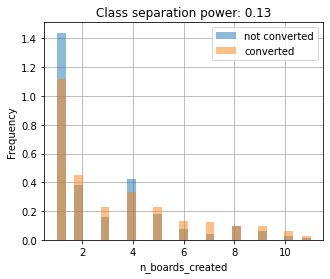

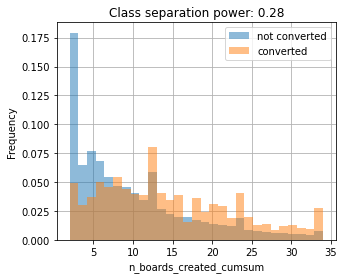

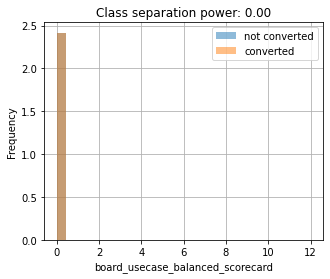

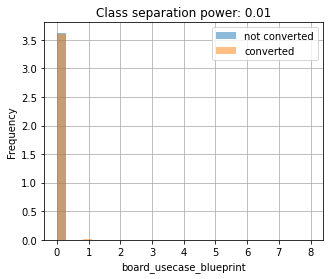

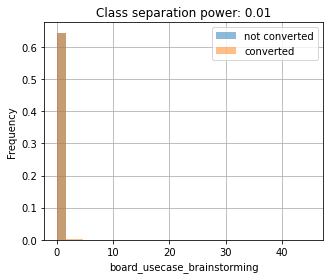

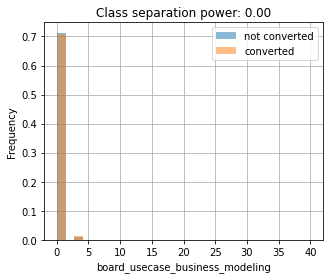

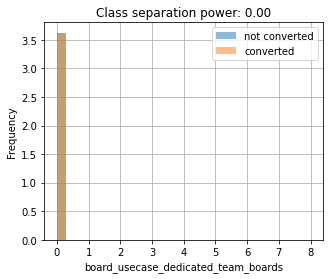

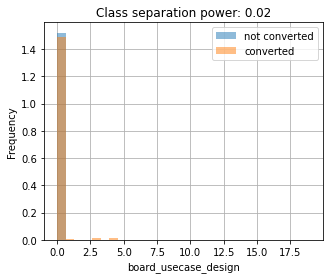

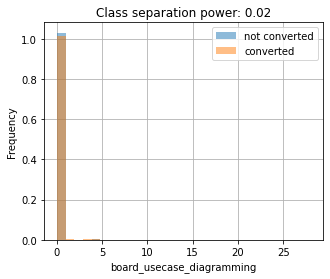

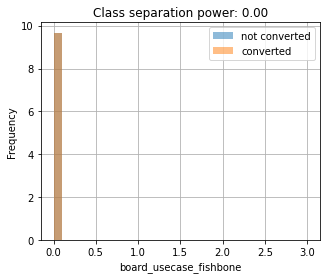

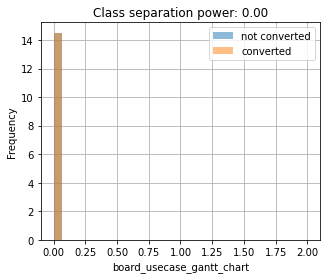

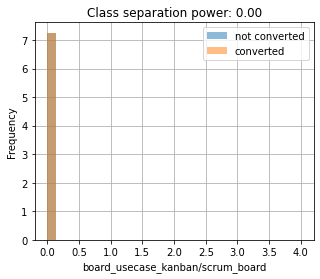

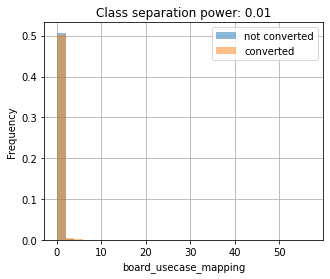

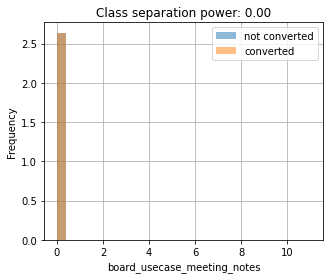

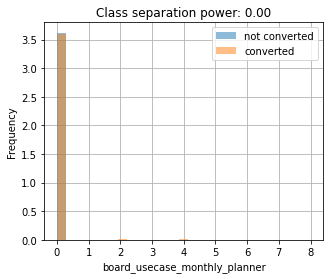

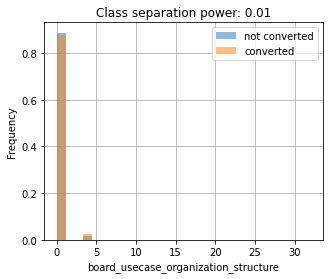

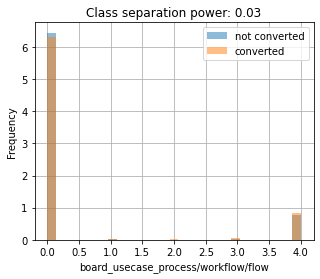

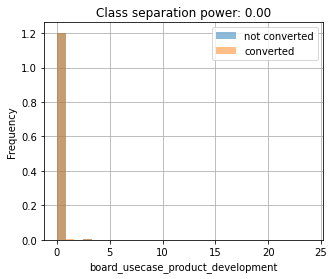

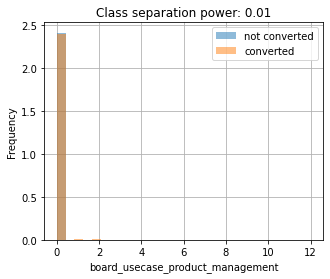

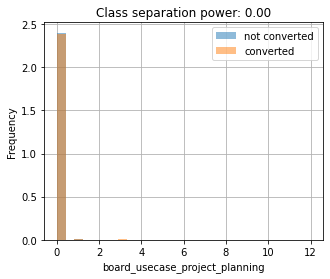

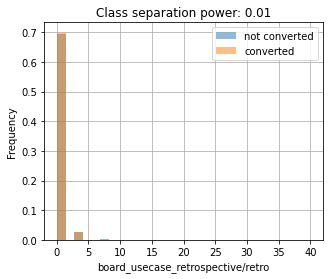

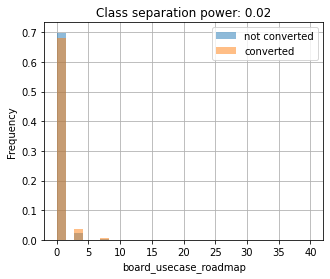

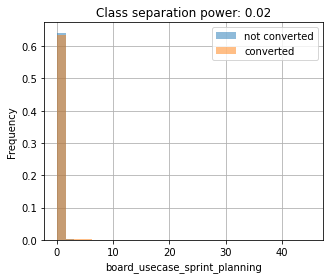

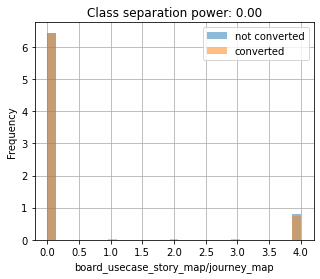

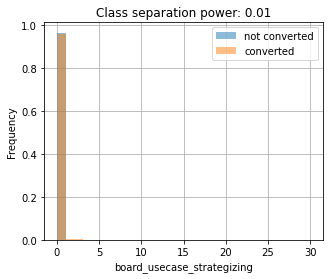

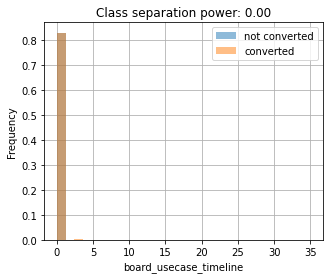

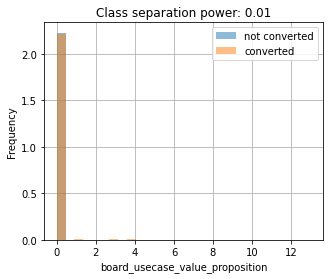

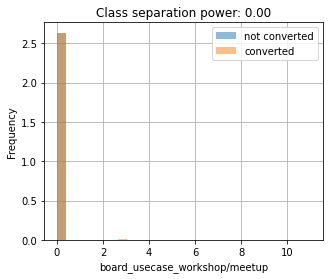

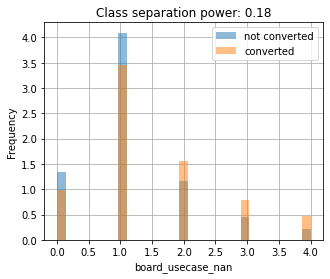

In [ ]:
get_features_stats('boards_stats',
                   cum_features = ['n_boards_created'],
                   extra_features = [c for c in dfs['boards_stats'].columns if c not in ['time', 'n_boards_created','account_id', 'target']])

## 2.3 Combine the useful features

In [ ]:
# drop uninformative features (ks score < separation_power_threshold)
separation_power_threshold = 0.1

# get the time stamp for the prediction week
last_data_week = max(df_labeled_data['time'].drop_duplicates())

df_training_application = (
    df_labeled_data
    [['account_id', 'time', 'domain', 'account_age_days', 'company_size', 'company_size_num', 'target']]
    .copy()
)

# add informative features from all the datasets
for df_nm in tqdm(dfs.keys()):
  # skip the accounts because it is already in df_training_application
  if df_nm == 'accounts':
    continue
  df = dfs[df_nm].copy()
  not_significant_features = []
  for col in df.columns:
    # skip non training features
    if col in ['time', 'account_id', 'company_size', 'target']:
      continue
    converted = df['target'] != 0.0
    valid_labels = df['time'] < last_data_week
    # assess how well the feature separates the converters from non-converters
    separation_power = ks_2samp(df[converted & valid_labels][col], df[~converted & valid_labels][col]).statistic
    if separation_power < separation_power_threshold:
      not_significant_features.append(col)
  # drop columns with very low separation power
  df.drop(columns=not_significant_features+['target'], inplace=True)

  # add the features
  df_training_application = df_training_application.merge(df, on=['account_id', 'time'], how='left')

100%|██████████| 6/6 [00:20<00:00,  3.50s/it]


## 2.4 Fill Nulls

In [ ]:
# assume accounts with no company domains belong to different companies
df_training_application['domain_fill'] = np.random.randint(np.nanmax(df_training_application['domain']), int(1e7), len(df_training_application))
df_training_application['domain'] = df_training_application['domain'].combine_first(df_training_application['domain_fill'])
df_training_application.drop(columns=['domain_fill'], inplace=True)
# fill the rest with -1
df_training_application = df_training_application.fillna(-1)

## Save/recover the prepared data

In [ ]:
df_training_fn = os.path.join(MIRO_DIR, 'df_training.pickle')

if 'df_training_application' in locals().keys():
  # save the data for further reuse
  with open(df_training_fn, 'wb') as f:
    pickle.dump(df_training_application, f)

# load the data
with open(df_training_fn, 'rb') as f:
  df_training_application = pickle.load(f)

## 2.5 Split into the training and application sets
Separate last week non conversion accounts from the rest to make conversion predictions

In [ ]:
is_latest_time_point = df_training_application['time'] == max(df_training_application['time'].drop_duplicates())
is_not_yet_converted = df_training_application['target'] == 0.0
is_application_account = is_latest_time_point & is_not_yet_converted

df_application = df_training_application[is_application_account].copy()
df_training = df_training_application[~is_application_account].copy()

X_app = df_application.drop(columns=['account_id', 'company_size', 'time', 'domain', 'target'])
X = df_training.drop(columns=['account_id', 'company_size', 'time', 'domain', 'target'])
y = df_training['target']
groups = df_training['domain']

### Check how correlated the features are

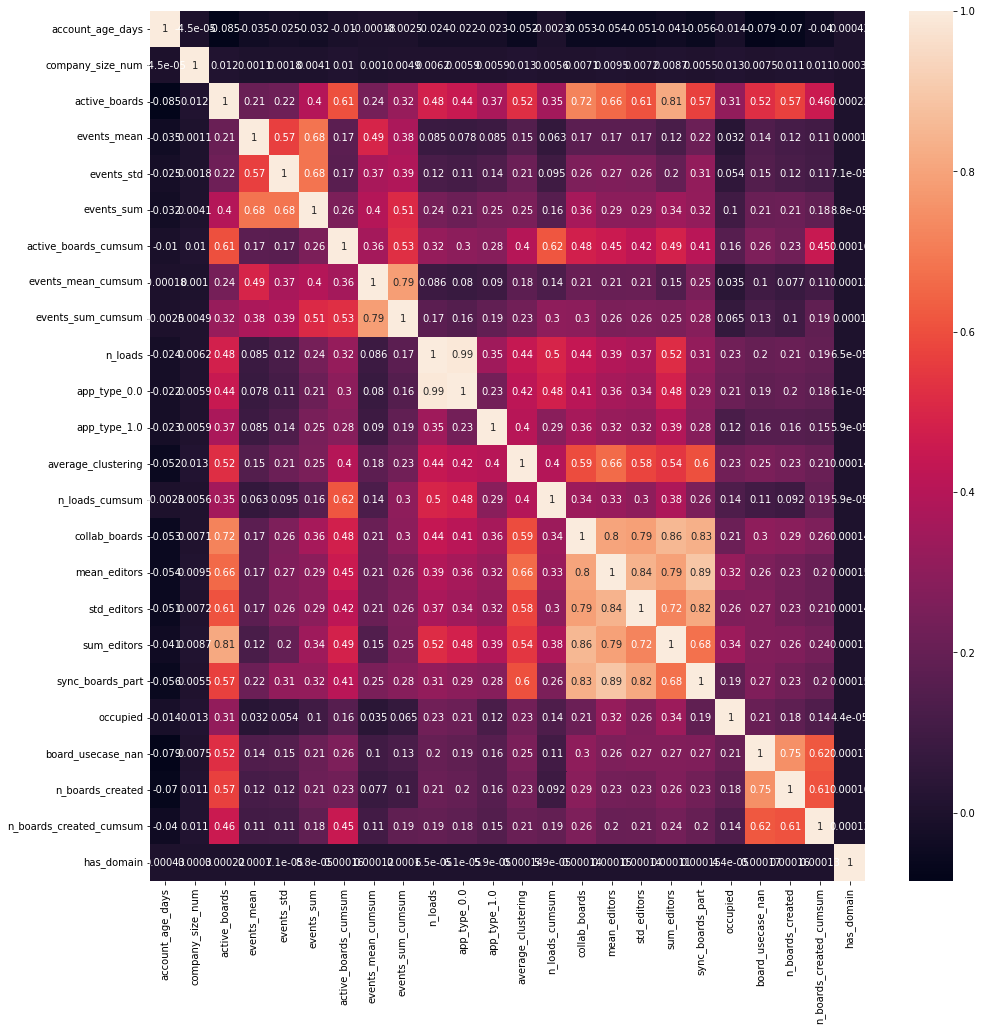

In [ ]:
corr_matrix = X.corr()
plt.figure(figsize = (16,16))
sns.heatmap(corr_matrix, annot = True)
plt.show()

No too large correlation between features pairs except for the case with `n_loads` and `app_type_0.0`, so kept them all

### Reduce the number of non conversion rows to keep CoLab away from failing too often

In [ ]:
p = 0.01

# trimming down the training dataset to speed up training
training_rows = (
    # randomly select p-th portion of the data
    np.random.choice(a=[False, True], size=len(y), p=[1-p, p])
    # along with samples with conversion
    | (y != 0.0)
    )

X = X[training_rows]
y = y[training_rows]
groups = groups[training_rows]
y.value_counts()

0.0    105602
1.0      2155
Name: target, dtype: int64

## 2.6 Model training
Decided to go with XGBoost because it:
* appears to be the best performing model on tabular data for the most cases
* handless the missing values well
* does not require feature scaling
* has mechanisms to account for class imballance



In [ ]:
# define the model
from xgboost import XGBClassifier

classifier = XGBClassifier(
    objective='binary:logistic',
    scale_pos_weight=sum(1-y)/sum(y),  # account for class imballance
)

### Search for the best set of parameters

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

params = { 'max_depth': [6, 10, 15, 20, 25, 30],
           'learning_rate': [0.01, 0.05, 0.1, 0.2, 0.3],
           'subsample': np.arange(0.5, 1.0, 0.1),
           'colsample_bytree': np.arange(0.2, 1.0, 0.1),
           'colsample_bylevel': np.arange(0.4, 1.0, 0.1),
           'n_estimators': [100, 500, 1000]}

scoring = 'f1' #‘roc_auc’ or ‘recall’ if don't care about false positives much

hp_search_clf = RandomizedSearchCV(
    estimator=classifier,
    param_distributions=params,
    scoring=scoring,
    cv=5,
    n_iter=50,
    return_train_score=True,
    verbose=2,
)

hp_search_clf.fit(X, y, verbose=False)

print(f"Best parameters: {hp_search_clf.best_params_}")
print(f"Best {scoring.upper()} score: {hp_search_clf.best_score_:.2f}")

Fitting 5 folds for each of 50 candidates, totalling 250 fits
[CV] END colsample_bylevel=0.6, colsample_bytree=0.8000000000000003, learning_rate=0.3, max_depth=15, n_estimators=100, subsample=0.7; total time=  25.8s
[CV] END colsample_bylevel=0.6, colsample_bytree=0.8000000000000003, learning_rate=0.3, max_depth=15, n_estimators=100, subsample=0.7; total time=  21.5s
[CV] END colsample_bylevel=0.6, colsample_bytree=0.8000000000000003, learning_rate=0.3, max_depth=15, n_estimators=100, subsample=0.7; total time=  21.5s
[CV] END colsample_bylevel=0.6, colsample_bytree=0.8000000000000003, learning_rate=0.3, max_depth=15, n_estimators=100, subsample=0.7; total time=  21.4s
[CV] END colsample_bylevel=0.6, colsample_bytree=0.8000000000000003, learning_rate=0.3, max_depth=15, n_estimators=100, subsample=0.7; total time=  22.0s
[CV] END colsample_bylevel=0.5, colsample_bytree=0.5000000000000001, learning_rate=0.1, max_depth=30, n_estimators=1000, subsample=0.5; total time= 2.3min
[CV] END cols

### Train the model

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

# use the parameters from the most recent hyperparameter search run if just performed
if 'hp_search_clf' in locals().keys() and hasattr('clf', 'best_params_'):
  best_params = hp_search_clf.best_params_
else:
  # use the parameters from previous hyperparameter search runs (takes too long to rerun every time)
  best_params = {'subsample': 0.8,
                 'n_estimators': 100,
                 'max_depth': 30,
                 'learning_rate': 0.01,
                 'colsample_bytree': 0.4,
                 'colsample_bylevel': 0.4}

# set the model parameters
classifier.set_params(**best_params)

# make sure accounts from the same company do not get split between training and testing
cv = StratifiedGroupKFold(n_splits=5, shuffle=True)

# train-test split
for train_idxs, test_idxs in cv.split(X, y, groups):
  classifier.fit(X.iloc[train_idxs, :], y.iloc[train_idxs])
  # one split would suffice
  break

### Assess model performance

Type I Error (fpr)          = 0.0311
Type II Error (fnr)         = 0.3318
Specificity (tnr)           = 0.9689
Precision                   = 0.3061
Recall (Sensitivity or tpr) = 0.6682
F1 Score                    = 0.4198
Kolmogorov-Smirnov score    = 0.7142



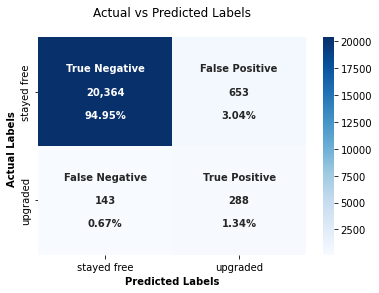

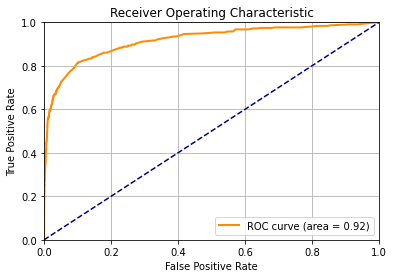

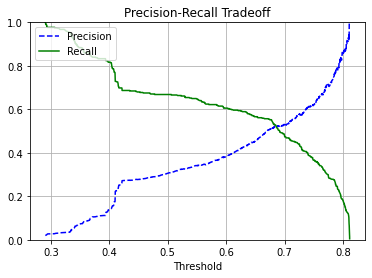

In [ ]:
display_classifier_performance_stats(classifier, X.iloc[test_idxs, :], y.iloc[test_idxs])

Observations:
* Much better than the baseline
* The majority of the conversions were identified
* Still a decent number of false positives

## 2.7 Feature importance

### Native xgboost feature importance assessment

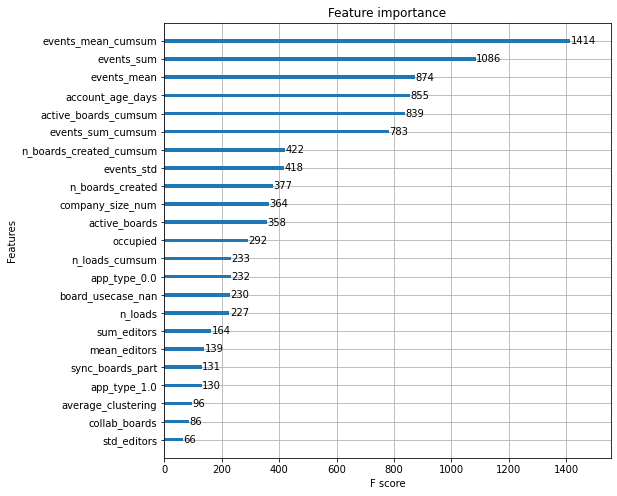

In [ ]:
from xgboost import plot_importance
fig, ax = plt.subplots(figsize = (8,8))
plot_importance(classifier, ax=ax);

### Additional model parameter effect explanation (shap values)

In [ ]:
import shap

explainer = shap.TreeExplainer(classifier)
shap_values = explainer.shap_values(X)

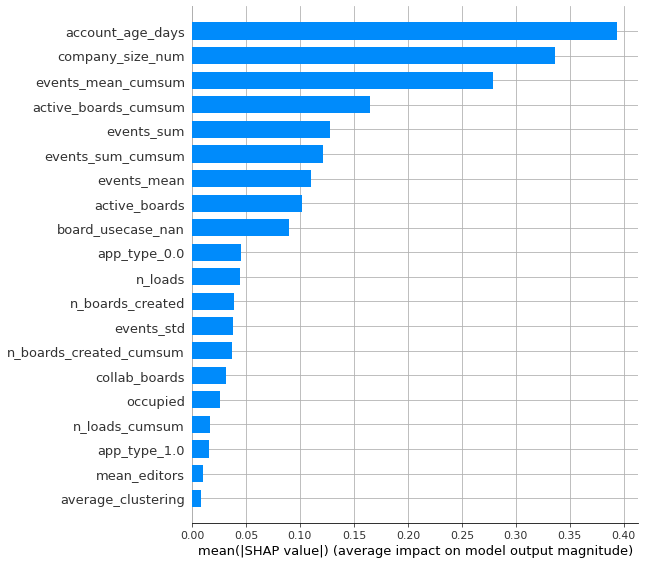

In [ ]:
# overall feature impact on the model
shap.summary_plot(shap_values, X, plot_type="bar")

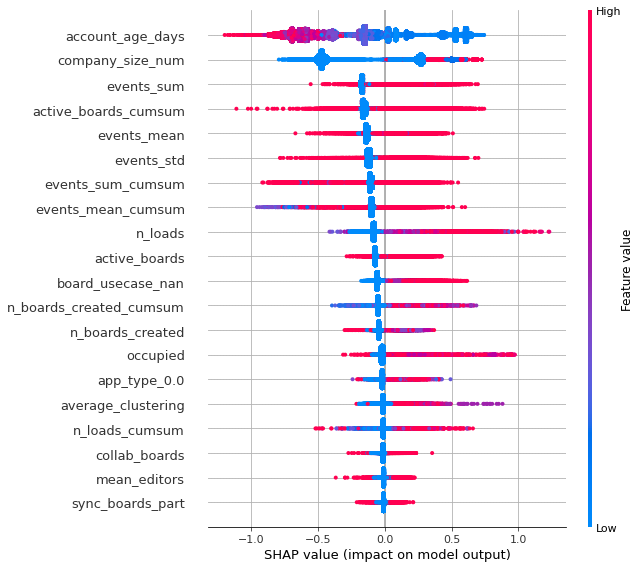

In [ ]:
# the effect of features polarity
shap.summary_plot(shap_values, X)

### Insights
* The longer the free use the smaller the probability of purchase
* Larger companies tend to buy licenses sooner
* A larger quantity of `events`, `created boards`, `occupied seats`, `loads` and other activity increase the probability of licence purchase though not immediately



## 2.8 Generate predictions

### Retrain with all data

In [ ]:
classifier.fit(X, y)

XGBClassifier(colsample_bylevel=0.4, colsample_bytree=0.4, learning_rate=0.01,
              max_depth=30, scale_pos_weight=49.00324825986079, subsample=0.8)

### Make predictions for the week of March 14th 2019

In [ ]:
df_application['Conversion Probability'] = classifier.predict_proba(X_app)[:,1]

print('Top 10 candidates for licence purchase')
display(
    df_application
    [['account_id', 'domain', 'company_size', 'account_age_days', 'Conversion Probability']]
    .sort_values('Conversion Probability', ascending=False)
    .set_index('account_id')
    .head(10)
)
df_application['Conversion Probability'].apply(lambda p: 'will switch' if p > 0.5 else 'will stay free').value_counts()

Top 10 candidates for licence purchase


,domain,company_size,account_age_days,Conversion Probability
account_id,,,,
428728,18925.0,2 - 50,21.0,0.811932
425867,8933.0,51 - 250,21.0,0.811928
428568,9019.0,2 - 50,21.0,0.811925
422827,65059.0,2 - 50,21.0,0.811925
429285,8483769.0,2 - 50,21.0,0.811897
408390,22450.0,2 - 50,28.0,0.811854
409645,79032.0,2 - 50,28.0,0.811850
430067,56795.0,5001 - 10000,21.0,0.811846
407605,8702337.0,2 - 50,28.0,0.811846


will stay free    425948
will switch        14355
Name: Conversion Probability, dtype: int64

### Save the result

In [ ]:
(
    df_application
    .sort_values('Conversion Probability', ascending=False)
    [['account_id', 'Conversion Probability']]
    .to_csv(os.path.join(MIRO_DIR, 'result.csv'), float_format='%.3f', index=False)
)

# Final thoughts

1. **Overpredicting**. I predicted ~14k accounts get converted on the week of March 14th 2019. That number seems pretty high considering the history. One of the reasons for that is the 100 times reduction in the training data for non converters which I made to speed up the computation and prevent the model training from failing (tried with all the samples - colab notebook was not happy). So, one way to make the predictions more realistic is to rerun the modeling on all data with a custom EC2 instance that has enough RAM to store the datasets while training. Another option might be spliting the data into batches and feeding those to the model one at a time. Hovewer, it moght not work with a sequential training model such as XGBoost but worth a further research. And the last, and easiest but not as precise, option would be to raise the score threshold to something higher than 0.5 to keep say the top 150 as actual conversion predictions.
2. **Data diversity**. The overwhelming proportion of the data exhibits user activity which, as shown by the analysis and common sense, is an indicator of conversion. The more activity in a form of boards/loads/seats/etc. the higher chance of license purchase. The almost only non activity feature is the company size which has a high enough importance according to shap values. This means that by diversifying data we can further improve the prediction quality. Another modality that I was thinking about was the text from the board contents themselves. Even a simple TF-IDF with an SVM or a neural net on top would be a nice addition worth ansambling for improved performance with the model I have already put together.
3. **LSTM**. I was thinking about putting a recurrent deep neural network for that task but ran out of time. I believe it has a potential given that it takes into consideration any changes in account activity as well as what happened in the most recent week. My major reservation against that is how rare the conversion events are for such a data hungry model as a deep net. Though, given an extended dataset with years 2020 and 2021 included that might pan out.
